# 13 · Vendor computer-use tools: the Claude computer toolset
Level L2 · Part 2 · professional · ~25 min · builds on 10, 12

## Goal
By the end you can declare Claude's `computer_toolset_20260801`, read the `tool_use` blocks it sends (one block per action, several per turn), run them on Pocket Tracker in order, answer each with a correct `tool_result` (including `zoom` images), and pick a screen size from the resolution table.

## The idea
In lesson 12 *we* defined the tools (`click(ref)`, `fill`, ...). A **computer-use tool** is the opposite: the vendor defines the actions and their arguments, the model is trained on them, and your harness only runs them. Claude's current **tool version** is `computer_toolset_20260801`: one entry in `tools` gives Claude an **action set** of 17 member tools (`screenshot`, `left_click`, `type`, `zoom`, ...). Each call is a separate `tool_use` block named after the action and marked `"toolset_name": "computer"`. No beta header is needed.

The model now acts in **pixels**, not refs, so the screenshot size matters again (lesson 10), and `zoom` lets it read small text at full resolution.

Analogy: a rental car. You no longer design the pedals; you learn the standard ones and keep the car (your harness) in good order.

## Picture
```mermaid
flowchart LR
  R["request<br/>tools: computer_toolset_20260801<br/>+ task + screenshot"] --> C[Claude]
  C -->|"tool_use blocks<br/>name = action<br/>toolset_name = computer"| H["harness:<br/>run in order,<br/>stop at first failure"]
  H --> P[Pocket Tracker page]
  H -->|"one tool_result per block<br/>(image for screenshot / zoom)"| C
```

## Step by step

### 1. Start Pocket Tracker
Same start as lesson 12: a scratch copy of the app on a free port, polled on `/health`. This time we leave the data as seeded, so the oldest open bug is #1.

In [1]:
import asyncio, atexit, base64, io, json, os, shutil, socket, subprocess, sys, time
from pathlib import Path
import httpx
from IPython.display import display
from PIL import Image
sys.path.insert(0, "..")    # course helpers: llm_setup, llm_replay

Copy the app, pick a free port, start the server and wait until it answers.

In [2]:
WORK, REPO = Path("../work/13"), Path("../work/13/pocket_tracker")
shutil.rmtree(WORK, ignore_errors=True)
shutil.copytree("../apps/pocket_tracker", REPO, ignore=shutil.ignore_patterns("*.db", "__pycache__", ".pytest_cache"))
with socket.socket() as s:
    s.bind(("127.0.0.1", 0))
    PORT = s.getsockname()[1]
BASE = f"http://127.0.0.1:{PORT}"
log = open(WORK / "server.log", "w")
server = subprocess.Popen([sys.executable, "-m", "uvicorn", "app:app", "--host", "127.0.0.1", "--port", str(PORT)],
                          cwd=REPO, env={**os.environ, "POCKET_TRACKER_DB": str((WORK / "pt.db").resolve())},
                          stdout=log, stderr=log)
atexit.register(server.terminate)
deadline = time.time() + 15
while True:
    try:
        print("health:", httpx.get(f"{BASE}/health").json()); break
    except httpx.ConnectError:
        if time.time() > deadline or server.poll() is not None:
            raise RuntimeError("server did not start; see ../work/13/server.log")
        time.sleep(0.2)

health: {'status': 'ok'}


### 2. A screen on a 2x display, live or recorded
Desktops are often high-DPI. We open the page at 1024x768 CSS pixels with `device_scale_factor=2`, so a full screenshot is 2048x1536. Browser cells are tagged `needs-download`. When they are skipped, the **recorded output** of a real run (`../data/recorded/13.json` and two PNGs) stands in.

In [3]:
REC = Path("../data/recorded")
REC_PATH = REC / "13.json"
seen = json.loads(REC_PATH.read_text()) if REC_PATH.exists() else {}
seen["source"] = "recorded output (real run, saved earlier)"
page = None                      # set by the browser cell below
DPR = 2
print("fallback keys:", sorted(k for k in seen if k != "source"))

fallback keys: ['boxes']


Start the browser and save the box of every link (in CSS pixels), so the recorded screen can tell what a click hits.

In [4]:
from playwright.async_api import async_playwright

pw = await async_playwright().start()
browser = await pw.chromium.launch()
page = await (await browser.new_context(viewport={"width": 1024, "height": 768}, device_scale_factor=DPR)).new_page()
await page.goto(f"{BASE}/issues")
seen["boxes"] = []
for loc in await page.locator("a").all():
    href, b = await loc.get_attribute("href"), await loc.bounding_box()
    seen["boxes"].append({"href": href, "text": (await loc.inner_text()).strip(),
                          "box": [round(b[k], 1) for k in ("x", "y", "width", "height")]})
await page.screenshot(path=WORK / "13_list_dpr2.png")
seen["source"] = "live run"
print("links:", len(seen["boxes"]), "| first issue link:", [b for b in seen["boxes"] if b["href"] == "/issues/1"])

⏭  Skipped: this cell needs [download]. Run it yourself, or re-run with TUT_ENABLE=download.


`Screen` is the display the harness controls. `capture()` takes the full-resolution image; `view()` halves it to 1024x768, the image Claude sees, so Claude's pixels equal CSS pixels. On the recorded screen, a click on the `/issues/1` link switches to the recorded issue page.

In [5]:
def hit(box, x, y):                                     # is (x, y) inside a recorded link box?
    bx, by, bw, bh = box
    return bx <= x <= bx + bw and by <= y <= by + bh

link1 = next(b for b in seen["boxes"] if b["href"] == "/issues/1")
print("(150, 284) hits the #1 link:", hit(link1["box"], 150, 284), "| (150, 320):", hit(link1["box"], 150, 320))

(150, 284) hits the #1 link: True | (150, 320): False


The class itself:

In [6]:
class Screen:
    FILES = {"/issues": "13_list_dpr2.png", "/issues/1": "13_issue1_dpr2.png"}    # recorded screens
    def __init__(self, page): self.page, self.rec_path = page, "/issues"
    def where(self):
        return self.page.url.removeprefix(BASE) if self.page else self.rec_path
    async def capture(self):                            # device pixels, 2048x1536
        if self.page:
            return Image.open(io.BytesIO(await self.page.screenshot()))
        return Image.open(REC / self.FILES[self.rec_path])
    async def view(self):                               # what Claude sees, 1024x768
        full = await self.capture()
        return full.resize((full.width // DPR, full.height // DPR), Image.LANCZOS)
    async def click(self, x, y, button="left", count=1):
        if self.page:
            await self.page.mouse.click(x, y, button=button, click_count=count)
            await self.page.wait_for_timeout(300)       # let a navigation start, then finish
            await self.page.wait_for_load_state()
        elif any(b["href"] == "/issues/1" and hit(b["box"], x, y) for b in seen["boxes"]):
            self.rec_path = "/issues/1"
    async def keys(self, action, value):                # type text or press a key, live only
        if self.page:
            await getattr(self.page.keyboard, action)(value)

screen = Screen(page)
print("screen:", "live page" if page else "recorded screen", "| Claude sees", (await screen.view()).size)

screen: recorded screen | Claude sees (1024, 768)


### 3. The resolution table
The toolset takes **no display size**: Claude's coordinates are in the pixels of the screenshots you send. The API does not shrink them either; an image over the model's limit is rejected (lesson 10). Every model that supports the toolset has the high-res limit: 2576 px on the long edge and 4784 image tokens. Copy `claude_tokens` and `resized_size` from lesson 10 and tabulate common screens.

In [7]:
import math

def claude_tokens(w, h):
    return math.ceil(w / 28) * math.ceil(h / 28)

def resized_size(width, height, max_edge=2576, max_tokens=4784):     # lesson 10, high-res defaults
    def fits(w, h):
        return (math.ceil(w / 28) * 28 <= max_edge and math.ceil(h / 28) * 28 <= max_edge
                and claude_tokens(w, h) <= max_tokens)
    if fits(width, height):
        return (width, height)
    aspect, lo, hi = width / height, 1, width
    while lo + 1 < hi:
        mid = (lo + hi) // 2
        lo, hi = (mid, hi) if fits(mid, max(round(mid / aspect), 1)) else (lo, mid)
    return (lo, max(round(lo / aspect), 1))

The docs' advice is in the last column: 1024x768 or 1280x720 for desktop tasks, 1280x800 or 1366x768 for web apps, nothing above 1920x1080.

In [8]:
ADVICE = {(1024, 768): "desktop", (1280, 720): "desktop", (1280, 800): "web apps", (1366, 768): "web apps",
          (1920, 1080): "upper limit", (2048, 1536): "too big: halve it", (3840, 2160): "too big: halve it"}
print(f"{'screen':>10} {'tokens':>7} {'sent as':>10} {'tokens':>7} {'scale':>6}  docs advice")
for w, h in ADVICE:
    sw, sh = resized_size(w, h)
    print(f"{w:>5}x{h:<4} {claude_tokens(w, h):>7} {sw:>5}x{sh:<4} {claude_tokens(sw, sh):>7} "
          f"{w / sw:>6.2f}  {ADVICE[w, h]}")

    screen  tokens    sent as  tokens  scale  docs advice
 1024x768     1036  1024x768     1036   1.00  desktop
 1280x720     1196  1280x720     1196   1.00  desktop
 1280x800     1334  1280x800     1334   1.00  web apps
 1366x768     1372  1366x768     1372   1.00  web apps
 1920x1080    2691  1920x1080    2691   1.00  upper limit
 2048x1536    4070  2048x1536    4070   1.00  too big: halve it
 3840x2160   10764  2576x1449    4784   1.49  too big: halve it


Our 2x screen (2048x1536, 4070 tokens) would fit the limit, but costs four times our 1024x768 view (1036). 4K must be shrunk to 2576x1449; the harness must then multiply every coordinate by 1.49. We halve instead: scale 2, which matches the CSS pixels Playwright clicks in, and keeps full detail available for `zoom`.

### 4. Declare the toolset
The `tools` entry is just `{"type": "computer_toolset_20260801"}`; all 17 members, including `zoom`, are on by default. `configs` switches members off. We will implement 11 members, so we withhold the other 6 rather than return errors for them, as the docs advise.

In [9]:
MEMBERS = ["screenshot", "zoom", "left_click", "right_click", "middle_click", "double_click", "triple_click",
           "left_click_drag", "mouse_move", "left_mouse_down", "left_mouse_up", "cursor_position",
           "scroll", "type", "key", "hold_key", "wait"]
WITHHELD = ["left_click_drag", "left_mouse_down", "left_mouse_up", "cursor_position", "scroll", "hold_key"]
TOOLS = [{"type": "computer_toolset_20260801",
          "configs": {name: {"enabled": False} for name in WITHHELD}}]
print(len(MEMBERS), "members;", len(MEMBERS) - len(WITHHELD), "enabled")
print(json.dumps(TOOLS[0])[:150], "...")

17 members; 11 enabled
{"type": "computer_toolset_20260801", "configs": {"left_click_drag": {"enabled": false}, "left_mouse_down": {"enabled": false}, "left_mouse_up": {"ena ...


Compare the previous version, `computer_20251124`: one tool named `computer`, an `action` field in every call, a display size, and the `anthropic-beta: computer-use-2025-11-24` header. Claude 5.5 models reject it on the Claude API and Google Cloud, and the toolset rejects its fields.

In [10]:
OLD_TOOL = {"type": "computer_20251124", "name": "computer",
            "display_width_px": 1024, "display_height_px": 768, "display_number": 1}
OLD_CALL = {"type": "tool_use", "id": "toolu_01", "name": "computer",
            "input": {"action": "left_click", "coordinate": [150, 284]}}
NEW_CALL = {"type": "tool_use", "id": "toolu_01", "name": "left_click", "toolset_name": "computer",
            "input": {"coordinate": [150, 284]}}
REJECTED_FIELDS = {"name", "display_width_px", "display_height_px", "display_number", "enable_zoom"}
print("old fields the toolset rejects:", sorted(REJECTED_FIELDS & OLD_TOOL.keys()))
print("old call:", OLD_CALL["name"], OLD_CALL["input"])
print("new call:", NEW_CALL["name"], NEW_CALL["toolset_name"], NEW_CALL["input"])

old fields the toolset rejects: ['display_height_px', 'display_number', 'display_width_px', 'name']
old call: computer {'action': 'left_click', 'coordinate': [150, 284]}
new call: left_click computer {'coordinate': [150, 284]}


### 5. The first request: task plus a screenshot
Same task as lesson 12. We attach the current screenshot to the first message, so Claude need not ask for one. An image block is base64 PNG.

In [11]:
SYSTEM = ("You operate the Pocket Tracker web app in a browser through the computer tools. "
          "Use zoom when text is too small to read. End each turn with a screenshot.")
TASK = ("Close the oldest open issue labelled 'bug'. Issues are numbered in the order they were filed, "
        "so a lower number is older. Do not change any other issue.")

def image_block(img):
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    return {"type": "image", "source": {"type": "base64", "media_type": "image/png",
                                        "data": base64.b64encode(buf.getvalue()).decode()}}

first_view = await screen.view()
messages = [{"role": "user", "content": [{"type": "text", "text": TASK}, image_block(first_view)]}]
print("image", first_view.size, "=", claude_tokens(*first_view.size), "tokens,",
      len(messages[0]["content"][1]["source"]["data"]) // 1024, "KB of base64")

image (1024, 768) = 1036 tokens, 181 KB of base64


### 6. One real call (only if a Claude recording or key exists)
This calls the `anthropic` SDK directly, because the toolset's blocks pass through it unchanged. `llm_replay` records the call once; with no recording and no `ANTHROPIC_API_KEY`, the cell is skipped. The model comes from `TUT_CU_MODEL` in `.env`, else the course's first Claude computer-use model.

In [12]:
import anthropic, llm_replay
from llm_setup import CATALOG, show_models
CU_MODEL = os.environ.get("TUT_CU_MODEL") if str(os.environ.get("TUT_CU_MODEL")).startswith("claude") else None
CU_MODEL = CU_MODEL or CATALOG["anthropic"]["computer_use"][0]
show_models("13_claude_computer_toolset", role="computer_use", chosen=f"anthropic:{CU_MODEL}")
llm_replay.start("13_claude_computer_toolset", model=f"anthropic:{CU_MODEL}",
                 key_env="ANTHROPIC_API_KEY", max_calls=2)
client = anthropic.Anthropic(api_key=os.environ.get("ANTHROPIC_API_KEY") or "replay-no-key-needed")
reply = client.messages.create(model=CU_MODEL, max_tokens=1024, system=SYSTEM, tools=TOOLS, messages=messages)
print("stop_reason:", reply.stop_reason, "| blocks:", [b.type for b in reply.content])

⏭  Skipped: this cell needs [llm]. Run it yourself, or re-run with TUT_ENABLE=llm.


When the cell above was skipped (this course was built without a Claude key, so there is no recording yet), we use a **hand-written reply in the documented format**: the shape of the batch example in Claude's docs, with coordinates taken from our recorded link boxes. It is not model output; it exists to exercise the harness. `Message.model_validate` turns it into the same SDK object a real call returns.

In [13]:
import anthropic

if "reply" not in globals():
    reply = anthropic.types.Message.model_validate({
        "id": "msg_handwritten", "type": "message", "role": "assistant", "model": "hand-written example",
        "stop_reason": "tool_use", "stop_sequence": None, "usage": {"input_tokens": 0, "output_tokens": 0},
        "content": [
            {"type": "text", "text": "Issue #1 is a bug and open. I'll open it."},
            {"type": "tool_use", "id": "toolu_A1", "name": "zoom", "toolset_name": "computer",
             "input": {"region": [620, 260, 820, 440]}},
            {"type": "tool_use", "id": "toolu_A2", "name": "left_click", "toolset_name": "computer",
             "input": {"coordinate": [150, 284]}},
            {"type": "tool_use", "id": "toolu_A3", "name": "screenshot", "toolset_name": "computer",
             "input": {}}]})
    print("[hand-written example in the documented format, not model output]")
print("model:", reply.model)

[hand-written example in the documented format, not model output]
model: hand-written example


### 7. Read the reply
Walk every block in order. Text is commentary; a `tool_use` block is a computer action only when `toolset_name == "computer"` (a custom tool could share a member's name). The action is the block's `name`; `input` holds only that action's arguments.

In [14]:
def computer_calls(reply):
    return [b for b in reply.content if b.type == "tool_use" and b.toolset_name == "computer"]

for b in reply.content:
    if b.type == "text":
        print("text:     ", b.text[:100])
for b in computer_calls(reply):
    print("tool_use: ", b.id, b.name, b.input)

text:      Issue #1 is a bug and open. I'll open it.
tool_use:  toolu_A1 zoom {'region': [620, 260, 820, 440]}
tool_use:  toolu_A2 left_click {'coordinate': [150, 284]}
tool_use:  toolu_A3 screenshot {}


Three actions in one turn: a **batch action**. Claude plans them together, and the harness runs them one after another, not in parallel, because each may depend on the one before.

### 8. Implement the members
Each member is a small function returning the `tool_result` content: an image for `screenshot` and `zoom`, `OK` for the rest. Coordinates are checked against the 1024x768 view first. Claude's key names are X11-style (`Return`, `ctrl+s`), so we translate them to Playwright's (`Enter`, `Control+s`).

In [15]:
VIEW_W, VIEW_H = 1024, 768
OK = [{"type": "text", "text": "OK"}]

def in_view(x, y):
    if not (0 <= x < VIEW_W and 0 <= y < VIEW_H):
        raise ValueError(f"coordinate ({x}, {y}) is outside the {VIEW_W}x{VIEW_H} screen")
    return x, y

def clicker(button, count):
    async def run(screen, coordinate, text=None):
        if text:
            raise ValueError("modifier clicks are not supported by this harness")
        await screen.click(*in_view(*coordinate), button=button, count=count)
        return OK
    return run

X11_TO_PW = {"Return": "Enter", "ctrl": "Control", "alt": "Alt", "shift": "Shift", "super": "Meta",
             "BackSpace": "Backspace", "Page_Down": "PageDown", "Page_Up": "PageUp"}

async def key(screen, text, repeat=1):
    combo = "+".join(X11_TO_PW.get(part, part) for part in text.split("+"))
    for _ in range(repeat):
        await screen.keys("press", combo)
    return OK

`zoom` gets a region `[x0, y0, x1, y1]` in screenshot pixels. It crops that region from the **full-resolution** capture (so times `DPR`) and shrinks it only if it would be bigger than the usual screenshot. Coordinates in later calls stay in the full screenshot's space, never the zoomed image's.

In [16]:
async def zoom(screen, region):
    x0, y0, x1, y1 = region
    in_view(x0, y0), in_view(x1 - 1, y1 - 1)
    crop = (await screen.capture()).crop((x0 * DPR, y0 * DPR, x1 * DPR, y1 * DPR))
    crop.thumbnail((VIEW_W, VIEW_H), Image.LANCZOS)       # keeps the aspect ratio, never enlarges
    return [image_block(crop)]

async def screenshot(screen):
    return [image_block(await screen.view())]

async def wait(screen, duration):
    await asyncio.sleep(min(duration, 5))                # the API allows up to 300 s; we cap it
    return OK

async def type_text(screen, text):
    await screen.keys("type", text)
    return OK

The dispatch table, keyed by member name. `mouse_move` is a no-op here (the page has no hover effects we need).

In [17]:
async def mouse_move(screen, coordinate):
    in_view(*coordinate)
    return OK

HANDLERS = {"screenshot": screenshot, "zoom": zoom, "left_click": clicker("left", 1),
            "right_click": clicker("right", 1), "middle_click": clicker("middle", 1),
            "double_click": clicker("left", 2), "triple_click": clicker("left", 3),
            "mouse_move": mouse_move, "type": type_text, "key": key, "wait": wait}
assert sorted(HANDLERS) == sorted(set(MEMBERS) - set(WITHHELD))
print("implemented:", sorted(HANDLERS))

implemented: ['double_click', 'key', 'left_click', 'middle_click', 'mouse_move', 'right_click', 'screenshot', 'triple_click', 'type', 'wait', 'zoom']


### 9. What zoom adds
Before running the batch, try `zoom` alone while the list is on screen. Look at one region two ways: cut from the 1024x768 view Claude normally sees, and as the zoom result.

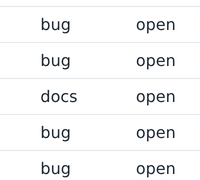

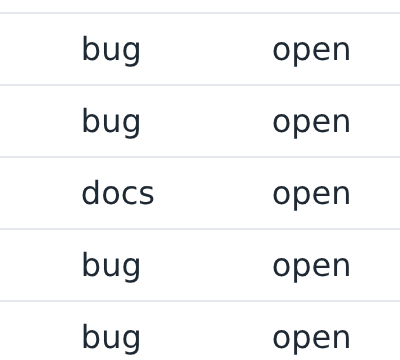

from the view: (200, 180) | from zoom: (400, 360) | tokens: 56 vs 195


In [18]:
region = (620, 260, 820, 440)               # Label and Status columns, rows #1-#5
zoomed = Image.open(io.BytesIO(base64.b64decode((await zoom(screen, region))[0]["source"]["data"])))
display(first_view.crop(region))
display(zoomed)
print("from the view:", first_view.crop(region).size, "| from zoom:", zoomed.size,
      "| tokens:", claude_tokens(*first_view.crop(region).size), "vs", claude_tokens(*zoomed.size))

Same cells, twice the pixels in each direction: the zoom costs 195 tokens instead of 56, a fifth of a full screenshot, and only when Claude asks for it. That is the trade the toolset makes: a cheap downscaled view every step, full detail on demand.

### 10. Run a batch: in order, stop at the first failure
The rules from Claude's docs: run blocks in order; one `tool_result` per `tool_use`, matched by `tool_use_id` and echoing `"toolset_name": "computer"`; a failed action gets `is_error: true` with a reason; every later block gets `is_error: true` with an exact **halt text**. A withheld or unknown member is an error too.

In [19]:
HALT = "Not executed: an earlier computer action in this turn failed."

def result(call, content, error=False):
    out = {"type": "tool_result", "tool_use_id": call.id, "toolset_name": "computer", "content": content}
    return {**out, "is_error": True} if error else out

async def run_batch(screen, reply):
    results, failed = [], False
    for call in computer_calls(reply):
        if failed:
            results.append(result(call, HALT, error=True)); continue
        try:
            if call.name not in HANDLERS:
                raise ValueError(f"action {call.name!r} is not available in this environment")
            results.append(result(call, await HANDLERS[call.name](screen, **call.input)))
        except (ValueError, TypeError) as e:
            results.append(result(call, f"Error: {e}", error=True)); failed = True
    return results

Run the reply from step 6 on the screen, then summarise what goes back to Claude.

In [20]:
results = await run_batch(screen, reply)
for call, r in zip(computer_calls(reply), results):
    kinds = [c["type"] for c in r["content"]] if isinstance(r["content"], list) else ["text"]
    sizes = [Image.open(io.BytesIO(base64.b64decode(c["source"]["data"]))).size
             for c in r["content"] if isinstance(r["content"], list) and c["type"] == "image"]
    print(f"{call.name:11} -> is_error={r.get('is_error', False)!s:5} {kinds} {sizes or ''}")
print("screen now shows:", screen.where())

zoom        -> is_error=False ['image'] [(400, 360)]
left_click  -> is_error=False ['text'] 
screenshot  -> is_error=False ['image'] [(1024, 768)]
screen now shows: /issues/1


With the hand-written reply: the zoom came back 400x360 (the 200x180 region at full 2x detail), the click on (150, 284) opened issue #1, and the final screenshot shows the issue page. With a real reply, your actions may differ; the harness is the same.

### 11. The next message
The results go back as one `user` message, after the assistant turn. In a loop (lesson 12) you would now call Claude again; here we stop after one step and only show the shape, with the image data shortened.

In [21]:
messages += [{"role": "assistant", "content": [b.model_dump(exclude_none=True) for b in reply.content]},
             {"role": "user", "content": results}]
short = json.loads(json.dumps(messages[-1]))
for r in short["content"]:
    for c in r["content"] if isinstance(r["content"], list) else []:
        if c["type"] == "image":
            c["source"]["data"] = c["source"]["data"][:12] + "..."
print(json.dumps(short, indent=1)[:900])

{
 "role": "user",
 "content": [
  {
   "type": "tool_result",
   "tool_use_id": "toolu_A1",
   "toolset_name": "computer",
   "content": [
    {
     "type": "image",
     "source": {
      "type": "base64",
      "media_type": "image/png",
      "data": "iVBORw0KGgoA..."
     }
    }
   ]
  },
  {
   "type": "tool_result",
   "tool_use_id": "toolu_A2",
   "toolset_name": "computer",
   "content": [
    {
     "type": "text",
     "text": "OK"
    }
   ]
  },
  {
   "type": "tool_result",
   "tool_use_id": "toolu_A3",
   "toolset_name": "computer",
   "content": [
    {
     "type": "image",
     "source": {
      "type": "base64",
      "media_type": "image/png",
      "data": "iVBORw0KGgoA..."
     }
    }
   ]
  }
 ]
}


Save the browser side of this run as the recording: link boxes and the two full-resolution screenshots. This runs only with a live browser.

In [22]:
await page.screenshot(path=WORK / "13_issue1_dpr2.png")
REC.mkdir(parents=True, exist_ok=True)
shutil.copy(WORK / "13_list_dpr2.png", REC / "13_list_dpr2.png")
shutil.copy(WORK / "13_issue1_dpr2.png", REC / "13_issue1_dpr2.png")
REC_PATH.write_text(json.dumps({k: v for k, v in seen.items() if k != "source"}, indent=1) + "\n")
print("saved", REC_PATH, "13_list_dpr2.png", "13_issue1_dpr2.png")

⏭  Skipped: this cell needs [download]. Run it yourself, or re-run with TUT_ENABLE=download.


## At work
- The vendor action set is the contract: a harness that ignores an argument (the toolset's newer `repeat` on `key`) silently does the wrong thing, and Claude 5.5 models refuse the older tool version, so teams pin model and tool version together and migrate them as one change → lesson 52.
- Claude's docs ask for a human check on consequential actions *before each block runs*, because one batch can finish a multistep action in a single turn → lesson 51.
- Screenshots are most of the bill: roughly 1,000–1,800 input tokens each, and past 20 images per request every image is held to 2000 px per side; teams use server-side tool-result clearing and caching rather than client-side pruning on Claude 5.5 models → lesson 43.
- The same task through OpenAI's `computer` tool (batched `actions[]`) and Gemini's `computer_use` (0–999 coordinates) needs a different adapter on the same harness → lesson 13a.

## What just happened
- You declared the **computer-use tool** as one entry, `{"type": "computer_toolset_20260801"}`, with no beta header and no display size, and used `configs` to withhold the 6 members you had not implemented.
- The **tool version** changed the message shape: the action moved from `input.action` to the block's `name`, and blocks carry `toolset_name`.
- The **action set** is fixed by the vendor; your harness implemented 11 members, including `zoom`, which crops the full-resolution capture.
- A **batch action** ran in order; every block got a `tool_result` with `toolset_name`, and the halt text is ready for a failure.
- The resolution table showed why we send a halved 1024x768 view of a 2x screen: a quarter of the tokens, and coordinates equal to CSS pixels.

## Common mistakes
A loop that answers only the first `tool_use` block, or forgets `toolset_name`. The API rejects such a request with an `invalid_request_error`. `check_answers` is our own imitation of those two rules (the real error text differs), applied to a lazy harness:

In [23]:
def check_answers(reply, results):
    calls = {c.id for c in computer_calls(reply)}
    answered = {r["tool_use_id"] for r in results}
    if calls - answered:
        raise ValueError(f"invalid_request_error (imitation): tool_use blocks without a tool_result: {calls - answered}")
    if any(r.get("toolset_name") != "computer" for r in results):
        raise ValueError("invalid_request_error (imitation): a tool_result for a computer member lacks toolset_name")
    return "ok"

first = computer_calls(reply)[0]
lazy = [{"type": "tool_result", "tool_use_id": first.id, "content": OK}]
check_answers(reply, lazy)

ValueError: invalid_request_error (imitation): tool_use blocks without a tool_result: {'toolu_A2', 'toolu_A3'}

Fix: answer every block, in order, through `result()`, as `run_batch` does.

In [24]:
print(check_answers(reply, results))

ok


Two more:
- Migrating by changing only `type`. Keeping `name`, `display_width_px`, `display_height_px`, `display_number` or `enable_zoom` on the toolset entry makes the request fail. Delete them, and remember zoom is now **on** by default.
- Sending the raw 2x capture "because it fits". It does fit (4070 tokens), but now Claude's pixels are device pixels, and clicking them as CSS pixels lands twice as far from the corner. Send one size and convert with one factor.

## Try it
Implement the withheld `scroll` member: inputs `scroll_direction` (`up`/`down`/`left`/`right`), `scroll_amount` (wheel clicks; use 100 px per click) and optional `coordinate`. On the live page use `page.mouse.move` then `page.mouse.wheel(dx, dy)`. Add it to `HANDLERS`, remove it from `WITHHELD`, rebuild `TOOLS`, and run a hand-written one-block reply `scroll` down 3 at (500, 400) followed by `screenshot` through `run_batch`. Then make a batch whose first block is a `left_click` at (1500, 300) and check that the later blocks get the halt text.

In [25]:
# your code here

## Key terms
- **computer-use tool** — a vendor-defined tool whose actions (screenshot, click, type, ...) the model is trained on; your harness runs them on a real screen and returns the results.
- **tool version** — the dated name of a vendor tool (`computer_toolset_20260801`, earlier `computer_20251124`); it fixes the message shape and the models that accept it.
- **action set** — the fixed list of actions a computer-use tool offers; Claude's toolset has 17 member tools, switched off one by one with `configs`.
- **batch action** — several `tool_use` blocks in one reply, run in order; the first failure stops the rest, which get the halt text.
- **zoom** — the toolset action that returns a region of the screen at full resolution, so the model can read small text without a bigger screenshot every step.

Always run this cell, and run it last: it closes the browser, stops the server and saves any model recording.

In [26]:
if "browser" in globals():
    await browser.close()
    await pw.stop()
server.terminate()
try:
    server.wait(timeout=10)
except subprocess.TimeoutExpired:
    server.kill(); server.wait()
log.close()
print("browser closed, server exit code", server.returncode)
import llm_replay
llm_replay.stop()

browser closed, server exit code -15
